# Maxwell: EM scattering and tag-reader coupling

Лабораторная работа • 3D + время • символьные и численные модели

**Вопрос:** как связать символьную запись Максвелла, граф вычислений, решение PDE и идентификацию параметров редуцированной модели?

Физические блоки демонстрируют разные режимы электродинамики. Оптические константы нельзя переносить на 13.56 MHz. Численные эксперименты не воспроизводят геометрию антенны из статьи.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import sympy as s
from IPython.display import display,Image,Markdown
from emlab.symbolic import *
from emlab.scattering import *
from emlab.coupling import *
metrics=json.loads((ROOT/'results/metrics.json').read_text())
def show(name): display(Image(filename=str(ROOT/'results'/f'{name}.png')))


## 1. Журнальные источники и постановка

- Sharif et al., Scientific Reports (2023), DOI **10.1038/s41598-023-39825-9**: Maxwell-поля и эквивалентная схема связи reader/tag. Используем идею двух связанных контуров, а не спорные размерности отдельных напечатанных формул.
- Abdelrahman et al., Scientific Reports (2017), DOI **10.1038/s41598-017-15192-0**: рассеяние на сфере, коэффициенты Ми.
- Malitson (1965) и Daimon & Masumura (2007): два независимых исследования дисперсии материалов, HTTP-копии из RefractiveIndex.INFO.

Внешние файлы содержат опубликованные дисперсионные аппроксимации, а не сырые измерения 3D-полей. Их назначение — вариативность материала в модели рассеяния. Данные RFID для подбора параметров синтетические.

In [2]:
display(json.loads((ROOT/'data/provenance.json').read_text()))

[{'name': 'silica',
  'url': 'https://raw.githubusercontent.com/polyanskiy/refractiveindex.info-database/master/database/data/main/SiO2/nk/Malitson.yml',
  'sha256': 'c587670f397241ecb93a1af3279d6fe7ed67888e587e399074b0eab729c92b52',
  'references': '1) I. H. Malitson.\nInterspecimen comparison of the refractive index of fused silica.\n<a href="https://doi.org/10.1364/JOSA.55.001205"><i>J. Opt. Soc. Am.</i> <b>55</b>, 1205-1208 (1965)</a><br>\n2) C. Z. Tan.\nDetermination of refractive index of silica glass for infrared wavelengths by IR spectroscopy.\n<a href="https://doi.org/10.1016/S0022-3093(97)00438-9"><i>J. Non-Cryst. Solids</i> <b>223</b>, 158-163 (1998)</a><br>\n* Sellmeier formula is reported in Ref. 1 for the 0.21–3.71 μm wavelength range. Ref. 2 verifies the validity of the formula up to 6.7 μm.\n',
  'retrieved_at_utc': '2026-10-29T04:35:32.226863+00:00',
  'kind': 'published dispersion fit, not raw field measurements'},
 {'name': 'water',
  'url': 'https://raw.githubuserco

## 2. Символьные модели

$$\epsilon\partial_t\mathbf E+\sigma\mathbf E+\mathbf J-\nabla\times\mathbf H=0,\qquad
\mu\partial_t\mathbf H+\nabla\times\mathbf E=0.$$
$$\nabla\cdot\mathbf D=\rho,\quad \nabla\cdot\mathbf B=0.$$

Компоненты зависят от $(x,y,z,t)$. Запись выше предполагает постоянные $\epsilon,\mu$; неоднородный численный солвер ниже использует $\mathbf D=\epsilon(\mathbf x)\mathbf E$.

Сравниваем SymPy Matrix (явные компоненты), sympy.vector (геометрические операторы) и SymEngine (независимый движок алгебры). Времена единичных вызовов не являются репрезентативным рейтингом библиотек.

In [3]:
for name,eq in models().items():
    display(Markdown(f'**{name}**')); display(eq)
display(compare_backends())

**ampere**

Matrix([
[epsilon*Derivative(Ex(x, y, z, t), t) + sigma*Ex(x, y, z, t) + Jx(x, y, z, t) + Derivative(Hy(x, y, z, t), z) - Derivative(Hz(x, y, z, t), y)],
[epsilon*Derivative(Ey(x, y, z, t), t) + sigma*Ey(x, y, z, t) + Jy(x, y, z, t) - Derivative(Hx(x, y, z, t), z) + Derivative(Hz(x, y, z, t), x)],
[epsilon*Derivative(Ez(x, y, z, t), t) + sigma*Ez(x, y, z, t) + Jz(x, y, z, t) + Derivative(Hx(x, y, z, t), y) - Derivative(Hy(x, y, z, t), x)]])

**faraday**

Matrix([
[mu*Derivative(Hx(x, y, z, t), t) - Derivative(Ey(x, y, z, t), z) + Derivative(Ez(x, y, z, t), y)],
[mu*Derivative(Hy(x, y, z, t), t) + Derivative(Ex(x, y, z, t), z) - Derivative(Ez(x, y, z, t), x)],
[mu*Derivative(Hz(x, y, z, t), t) - Derivative(Ex(x, y, z, t), y) + Derivative(Ey(x, y, z, t), x)]])

**gauss_B**

mu*Derivative(Hx(x, y, z, t), x) + mu*Derivative(Hy(x, y, z, t), y) + mu*Derivative(Hz(x, y, z, t), z)

**gauss_D**

epsilon*Derivative(Ex(x, y, z, t), x) + epsilon*Derivative(Ey(x, y, z, t), y) + epsilon*Derivative(Ez(x, y, z, t), z) - rho(x, y, z, t)

{'sympy_matrix_curl': 'Matrix([[-x**2 + 2*x*y], [-y**2 + y], [2*x*z - z]])',
 'sympy_vector_curl': '(-C.x**2 + 2*C.x*C.y)*C.i + (-C.y**2 + C.y)*C.j + (2*C.x*C.z - C.z)*C.k',
 'sympy_vector_div': '0',
 'vector_seconds': 0.005702994999865041,
 'matrix_vector_curl_equal': True,
 'symengine_derivative_equal': True,
 'symengine_seconds': 0.003548745999978564}

## 3. Отображения полей и тождества

Градиент: R³→R³ для скалярного поля; ротор: векторное поле→векторное поле; дивергенция возвращает скаляр. Дополнительно: скалярное/векторное произведение, матрица Якоби, векторный лапласиан.

In [4]:
f=x*x*y+s.sin(z)
F=s.Matrix([y*z,x*x*z,x*y*y]);G=grad(f)
display({'gradient':G,'curl':curl(F),'divergence':div(F),'dot':F.dot(G),
         'cross':F.cross(G),'Jacobian':F.jacobian(XYZ),
         'vector Laplacian':s.Matrix([div(grad(v)) for v in F])})
assert curl(grad(f))==s.zeros(3,1)
assert s.simplify(div(curl(F)))==0
print('curl(grad f)=0; div(curl F)=0: verified')

curl(grad f)=0; div(curl F)=0: verified


{'gradient': Matrix([
 [ 2*x*y],
 [  x**2],
 [cos(z)]]),
 'curl': Matrix([
 [-x**2 + 2*x*y],
 [    -y**2 + y],
 [    2*x*z - z]]),
 'divergence': 0,
 'dot': x**4*z + 2*x*y**2*z + x*y**2*cos(z),
 'cross': Matrix([
 [-x**3*y**2 + x**2*z*cos(z)],
 [  2*x**2*y**3 - y*z*cos(z)],
 [    -2*x**3*y*z + x**2*y*z]]),
 'Jacobian': Matrix([
 [    0,     z,    y],
 [2*x*z,     0, x**2],
 [ y**2, 2*x*y,    0]]),
 'vector Laplacian': Matrix([
 [  0],
 [2*z],
 [2*x]])}

## 4. Словарь, граф выражения, матрица смежности

`equations.json` хранит каноническую запись `srepr`. Для одного компонентного уравнения строится дерево вхождений AST: ребро parent→operand. Повторные выражения сохраняют разные ID; подписи и порядок узлов записаны отдельно. Это граф вычисления выражения, а не пространственная сетка и не причинный граф.

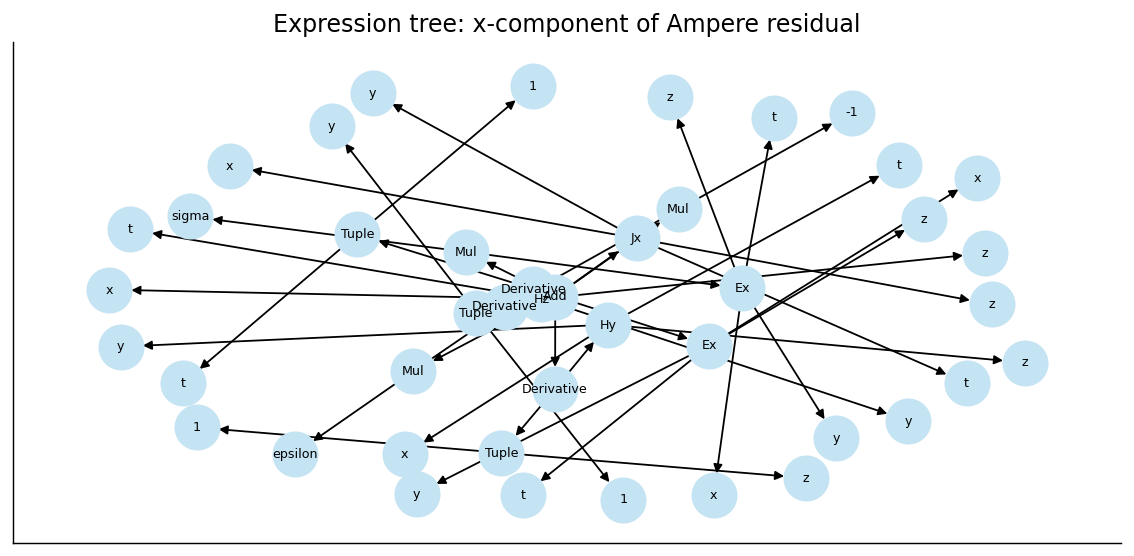

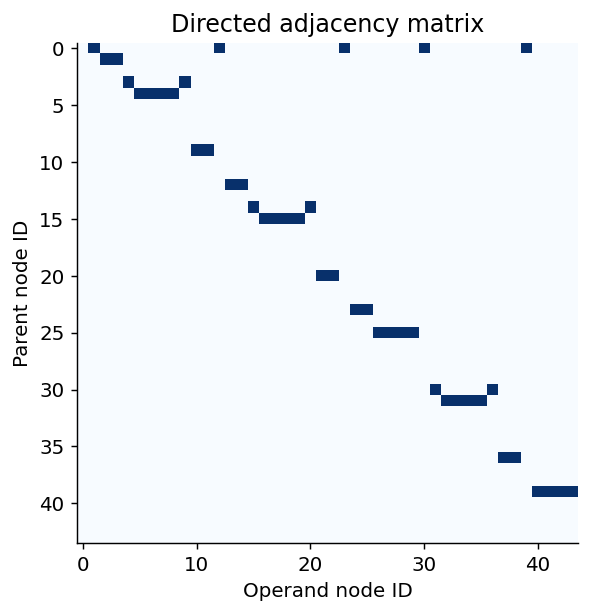

In [5]:
show('expression_graph');show('adjacency')

## 5. Рассеяние: точная модель и аппроксимация

Немагнитная сфера радиуса $a$ в вакууме:
$$Q_{sca}=\frac{2}{x^2}\sum_{n=1}^{N}(2n+1)(|a_n|^2+|b_n|^2),\quad x=2\pi a/\lambda.$$
В пределе $x\ll1$:
$$Q_R=\frac83x^4\left|\frac{m^2-1}{m^2+2}\right|^2.$$

Волны монохроматические: физическое поле восстанавливается как Re[E(r) exp(-iωt)]. Фазовая конвенция не меняет Q. Используем прозрачные материалы и диапазон 0.45–1 μm, радиус 25 nm. CSV содержит n(λ), Ми и Рэлей.

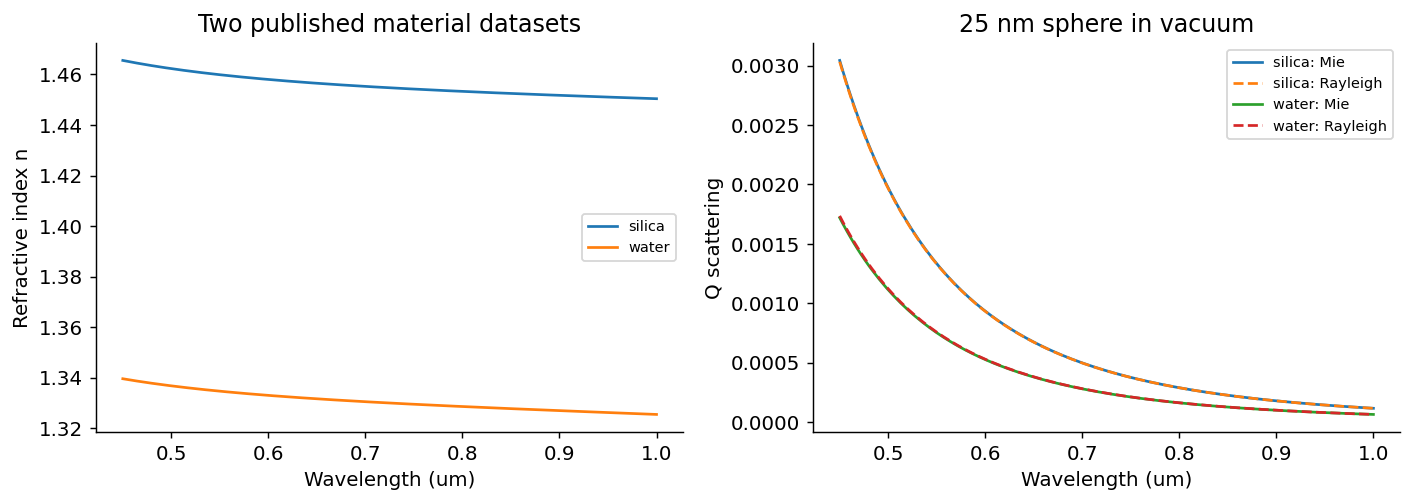

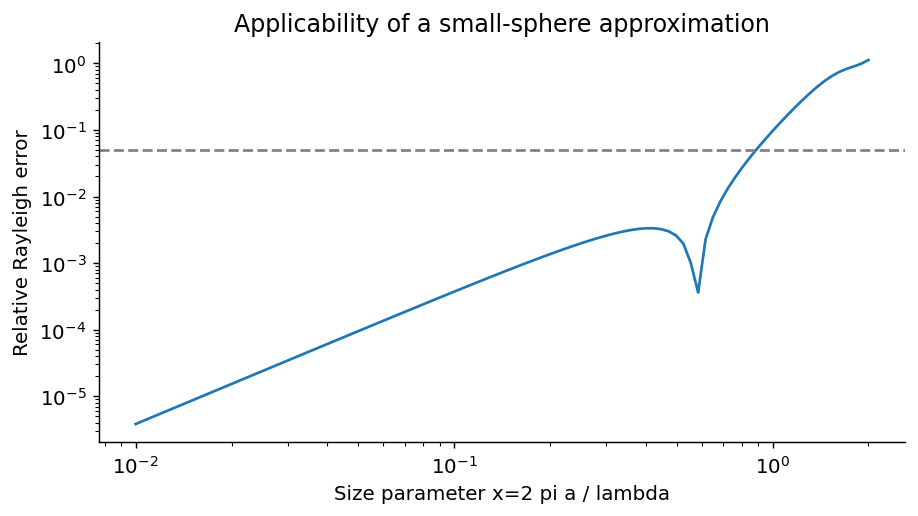

{'silica_rayleigh_max_relative_error': 0.0036046905173092387,
 'water_rayleigh_max_relative_error': 0.009259031664719825}

In [6]:
show('materials_scattering');show('rayleigh_error')
display({k:v for k,v in metrics.items() if 'rayleigh' in k})

## 6. Полное 3D-решение Максвелла во времени

Нормированные единицы $c=\epsilon_0=\mu_0=1$, $\Omega=[0,1)^3$, периодические границы:
$$\dot{\mathbf D}=\nabla_h\times\mathbf H,\qquad
\dot{\mathbf H}=-\nabla_h\times(\mathbf D/\epsilon(\mathbf x)).$$

Начальные данные $D_y=H_z=\cos(2\pi x)$, остальные компоненты нулевые. Материал: сглаженная сфера $\epsilon=1+1.1\exp[-(r/0.14)^8]$. Шаги: центральные разности O(h²), RK4, 24³ узла, 160 шагов до t=0.65.

Плоская начальная волна и сферическая неоднородность формируют поле, зависящее от трёх пространственных координат. Разность с однородным IVP показывает возмущение; начальные E внутри включения различаются. Это **периодическая начальная задача**, а не изолированная сфера с условием излучения. Её нельзя сравнивать напрямую с far-field Q из Ми.

Stored vector fields: (21, 3, 24, 24, 24) time frames and 3 components on 3D grid


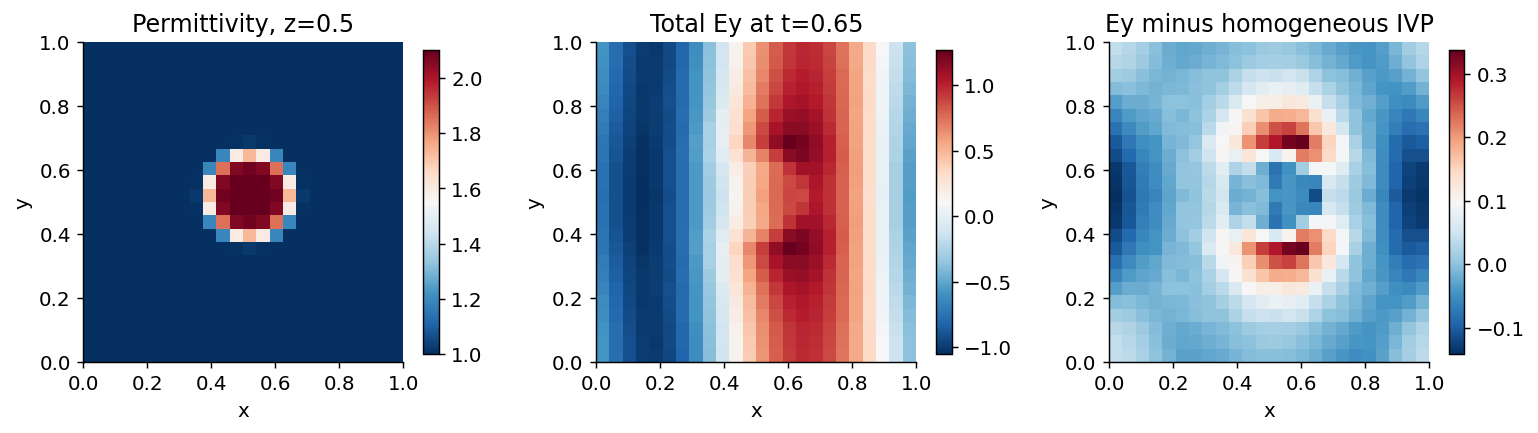

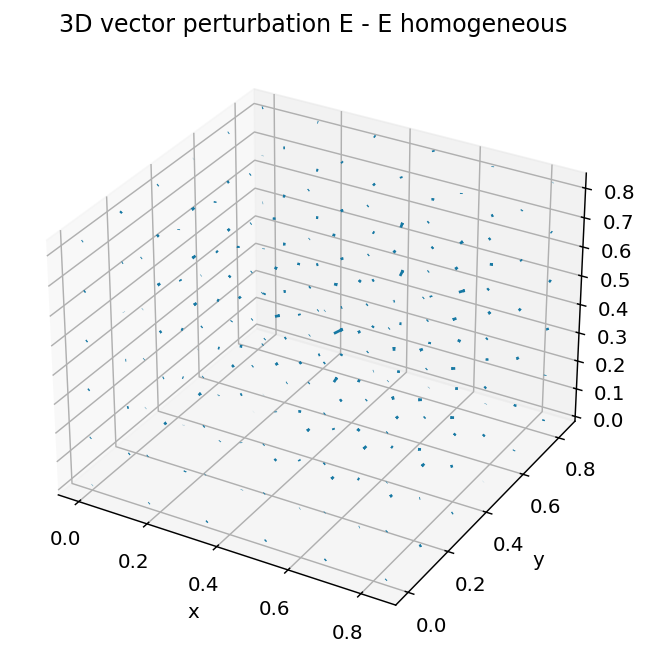

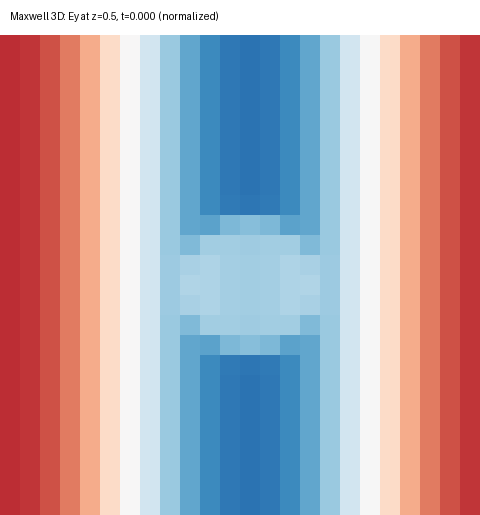

In [7]:
show('maxwell_slices');show('maxwell_3d');display(Image(filename=str(ROOT/'results/maxwell_evolution.gif')))
f=np.load(ROOT/'results/fields_3d.npz')
print('Stored vector fields:',f['E'].shape,'time frames and 3 components on 3D grid')

## 7. Проверка решения

Смотрим дискретные div D, div H и дрейф энергии. Для однородной среды отдельно сравниваем с точной плоской волной cos[2π(x−t)] на сетках 12³, 24³, 48³. Это количественная проверка порядка схемы; гладкая неоднородная сфера не имеет здесь независимого точного решения.

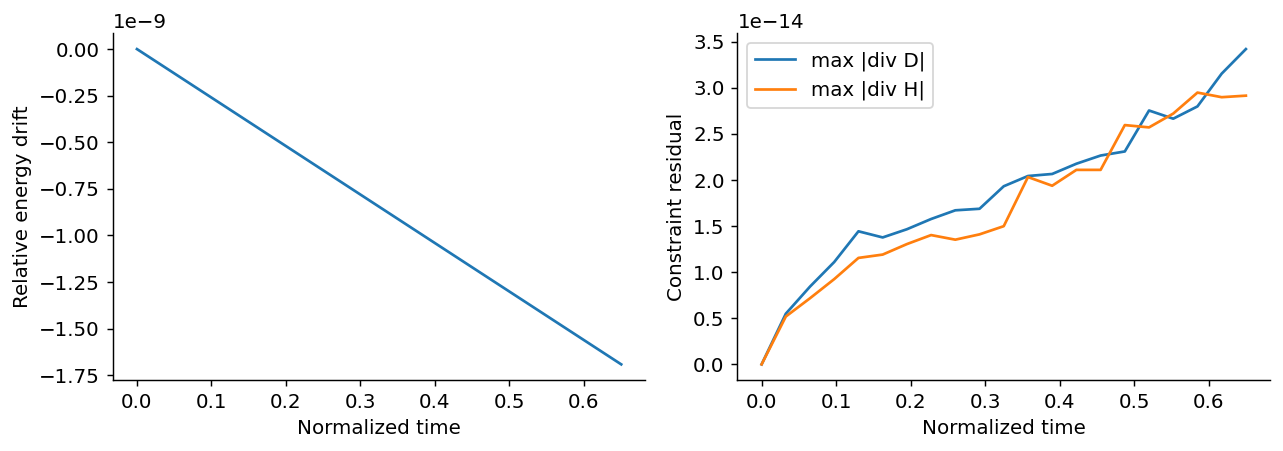

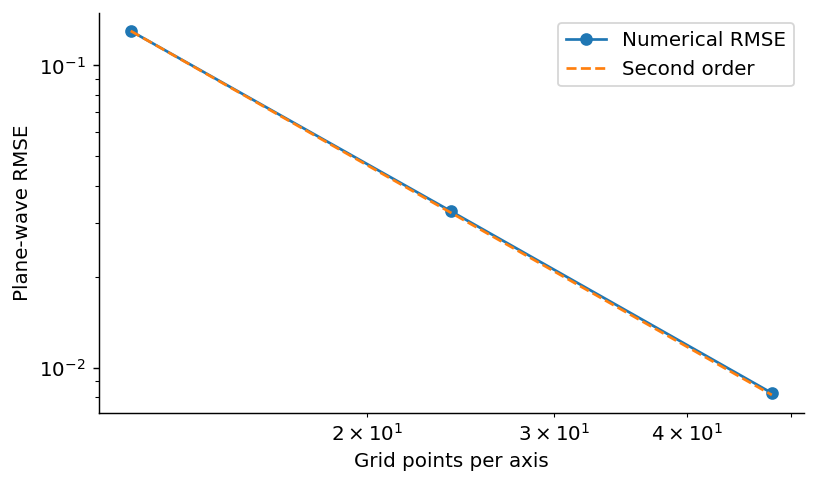

{'maxwell_energy_relative_drift': 1.6914906142417863e-09,
 'maxwell_max_divD': 3.419486915845482e-14,
 'maxwell_max_divH': 2.9476421303797906e-14,
 'plane_wave_grid_sizes': [12, 24, 48],
 'plane_wave_rmse': [0.12997385365956932,
  0.03287280396019466,
  0.00824004747470359],
 'plane_wave_orders': [1.9832550063092353, 1.9961699650298665]}

In [8]:
show('conservation');show('convergence')
display({k:v for k,v in metrics.items() if k.startswith(('maxwell','plane_wave'))})

## 8. Геометрия reader/tag → взаимная индуктивность

$$M=\frac{\mu_0}{4\pi}\oint\oint\frac{d\boldsymbol\ell_1\cdot d\boldsymbol\ell_2}{|\mathbf r_1-\mathbf r_2|}.$$

Две круговые катушки: 40 и 15 mm, расстояние 40 mm, воздушная среда, один виток. Интеграл Неймана вычисляется квадратурой по 240 точкам. Можно менять положение и наклон в 3D. При 13.56 MHz длина волны около 22 m: размеры намного меньше λ. Собственные L задаются отдельно; формула для тонких пересекающихся проводов неприменима.

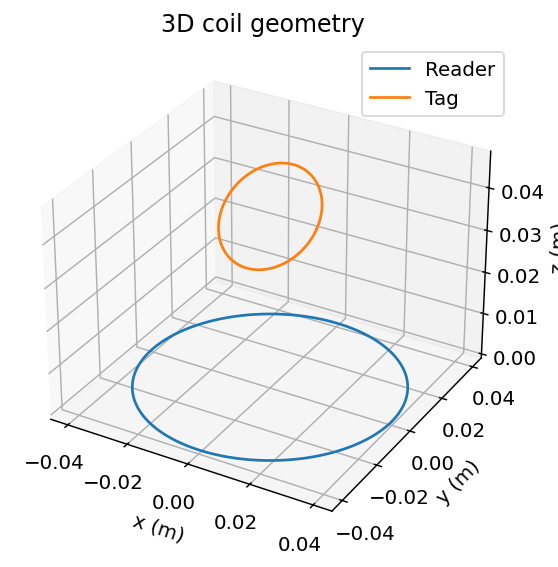

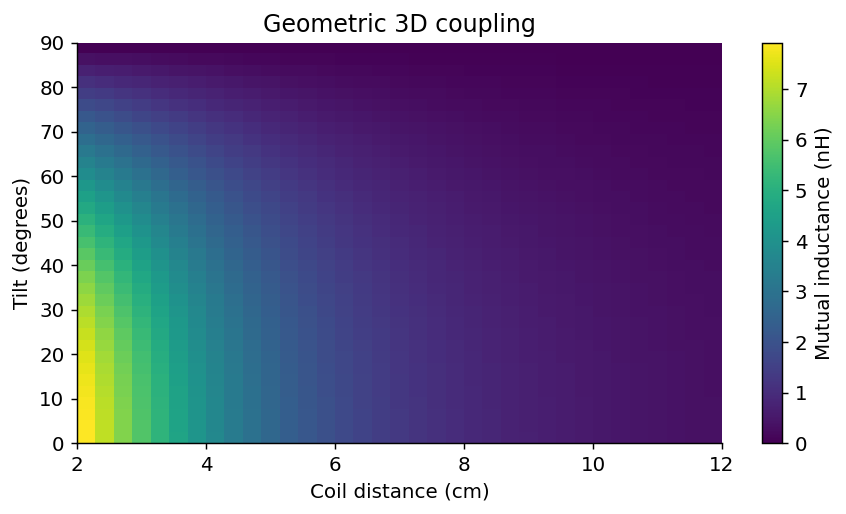

In [9]:
show('coils_3d');show('coupling_map')

## 9. Уточнение параметров модели-решения ODE

$$\begin{bmatrix}L_1&M\\M&L_2\end{bmatrix}\dot{\mathbf i}
+\operatorname{diag}(R_1,R_2)\mathbf i+
\operatorname{diag}(1/C_1,1/C_2)\mathbf q=\begin{bmatrix}V_s\\0\end{bmatrix},\quad\dot{\mathbf q}=\mathbf i.$$

$L_1=1$ μH, $L_2=0.5$ μH, $R_1=2$ Ω, $R_2=4$ Ω. C настроены на 13.56 MHz. Начальные токи и напряжения нулевые; Vs=cos(2πft) V.

Вектор θ=(M [nH], R₂ [Ω]); начальная точка (12,6), bounds ([0.1,0.5],[100,15]). Ожидаемые значения: M из геометрии, R₂=4 Ω. Пассивность: M²<L₁L₂. DOP853 решает ODE, least_squares минимизирует нормированные остатки.

Шум Gaussian, σ=1% peak current, seed фиксирован. Каждая третья точка исключена из fit; held-out RMSE считается относительно известной чистой траектории. Это интерполяционная проверка на той же траектории, не проверка на новом устройстве.

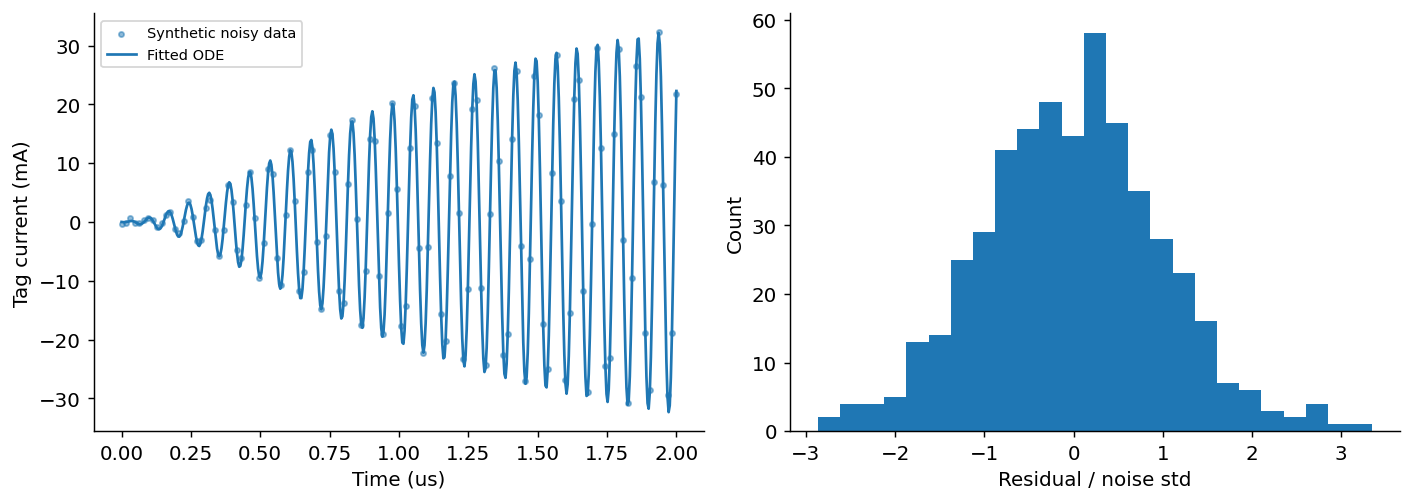

{'true_M_nH': 3.7673022060741843,
 'fitted_M_nH': 3.8261705665770176,
 'true_R2_ohm': 4.0,
 'fitted_R2_ohm': 4.0729760061665905,
 'heldout_rmse_A': 2.738743093182639e-05,
 'noise_std_A': 0.00032395488923171094,
 'jacobian_rank': 2,
 'nfev': 10}

In [10]:
show('parameter_fit');display(metrics['coupling_fit'])

## 10. Смешанные модели

`HybridModel` объединяет геометрию M(d, tilt), добавочную функцию ΔM(features) и физический ODE-солвер. По умолчанию поправка нулевая. Это интерфейс для будущей обучаемой поправки; нейросеть не обучена и улучшение качества не заявлено. Пассивность проверяется после поправки.

In [11]:
hybrid=HybridModel();tt=np.linspace(0,1e-7,20);print('Hybrid output shape:',hybrid.predict(tt).shape)

Hybrid output shape: (4, 20)


## 11. Выводы и ограничения

1. Символьная модель сохранена как словарь, AST-граф и матрица смежности; проверены векторные тождества.
2. Рэлей проверен против Ми, а не выдан за точное решение при произвольном размере сферы.
3. 3D Maxwell IVP проверен по ограничениям, энергии и сходимости плоской волны.
4. M и R₂ восстановлены по синтетическому переходному процессу; значения и ошибки находятся выше.
5. Реализован интерфейс физической модели с корректирующей функцией.

**Что потребует данных преподавателя:** если нужны именно два набора экспериментальных 3D+time полей или реальные reader/tag измерения, опубликованные дисперсионные коэффициенты и синтетическая траектория это требование не заменяют. В приложенном PDF конкретные датасеты для этой темы не указаны.

Тесты: `python -m pytest -q`. Воспроизведение: см. README. Использование ИИ раскрыто в `docs/AI_USAGE.md`.